# Pulsed EPR Molecular Distance Distribution

Recover a molecular spin-distance probability distribution and nuisance physical parameters from measured complex four-pulse EPR echoes with intermolecular background decay and missing distance resolution.

This maintainer notebook actively reconstructs the complete bound observations with local numerical modules. It distinguishes the independently reproduced original method from fresh cleaned results. There is no cache-preview path. The paper describes the selected model; the exact bound dataset and modern port have separate provenance.

## Observation and inverse problem

For evolution time t in microseconds and spin separation r in nm, the orientation-averaged intramolecular kernel is
```math
K(t,r)=\int_0^1\cos\!\left[\frac{D\,10^{21}}{r^3}|t-t_0|(1-3u^2)\right]du,
\qquad V(t)=B(t)\int[(1-\lambda)+\lambda K(t,r)]P(r)dr.
```
The orientation variable u is the cosine of the angle between spin separation and the magnetic field, D is the electron dipolar constant in rad·m³/s, t0 is refocusing time, lambda is modulation depth, P is the normalized distance density (1/nm), and B is homogeneous intermolecular decay. Instrument quadrature data have an unknown overall phase and amplitude. B(t)=exp[-κ lambda c D |t-t0| 10^-6], where κ=8π²/(9√3) and c is spin number density in m^-3. A concentration C in micromol/L gives c=C·10^-3·NA, with NA the Avogadro constant. The model assumes randomly oriented spin pairs, identical relaxation rates and no orientation selection or hyperfine modulation.

The complete bound observation contains 263 complex echoes. The requested model has two Gaussian distance populations and estimates both background concentration and refocusing time; limited evolution time cannot uniquely establish arbitrary substructure.

## Implemented mathematics and numerical conventions

Use t=raw_time-raw_time[0]+0.1 microsecond and r=arange(1.5,6,0.01) nm. Phase correction minimizes the summed squared imaginary part: phi=atan2(sum(Re V Im V),sum((Im V)²-(Re V)²)/2)/2+π/2. Rotate by exp(i phi), flip sign if the real mean is negative, then divide by the maximum real signal. No imaginary-to-magnitude substitution occurs.

Let phi_ij=|t_i| D 10^21/r_j³, q_ij=sqrt(6 phi_ij/π), and Fresnel integrals S(q),C(q) use the standard πv²/2 argument. K0=[C(q)cos(phi)+S(q)sin(phi)]/q, with exact limit K0(0,r)=1. Multiply each distance column by trapezoidal r weights. D=mu0*(g muB)²/(2h) using constants copied verbatim from source.

Preserve upstream cubic time interpolation: dt=mean(diff(t)); base time grid is arange(min(t)-0.3-0.048-dt,max(t)+0.3+0.048+dt,dt). Interpolate the weighted kernel to t-t0. The homogeneous background uses |t-t0|, concentration micromol/L times 1e-3 NA and microseconds times 1e-6. The total kernel is B*((1-lambda)*distance_weights+lambda*K0_weighted).

Gaussian columns q_jk=exp(-(r_j-mu_k)²/(2sigma_k²))/(sqrt(2π)sigma_k) share the denominator sum_k trapezoid(q_k,r); this is the upstream common-basis amplitude convention, not separately normalized columns. For nonlinear theta=[lambda,t0,C,mu1,sigma1,mu2,sigma2], solve min_(a>=0)||A(theta)a-y||² with scipy.optimize.nnls, then optimize the unnormalized data residual using scipy.optimize.least_squares, trust-region reflective default, max_nfev=1000, ftol=xtol=gtol=1e-10. Start=[0.01,0.3,50,2.5,0.2,4.5,0.2]. Bounds=[0,0.252,0.01,1,0.05,1,0.05] to [1,0.348,5000,20,2.5,20,2.5]. No regularizer is used for this parametric model.

Normalize the final weighted Gaussian sum to unit trapezoidal integral, but keep the unnormalized amplitudes for the fitted echo and reported amplitude parameters. Component labels are exchangeable, so use increasing fitted mean consistently for the parameter contract and oracle comparison; this is a declared label convention, not a phase/scale alignment. Notebook experiments recompute shortened evolution records and time-calibration perturbations. They do not establish extra molecular species or physical truth.

In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json,subprocess,hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),Path.cwd().parent] if (p/'src').is_dir())
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.main import run
from src.visualization import make_figures,relative_error
data=load_data()
display(Markdown('| Observation | Internal shape | Dtype |\n| --- | --- | --- |\n'+'\n'.join(f'| {k} | {v.shape} | {v.dtype} |' for k,v in data.items())))

| Observation | Internal shape | Dtype |
| --- | --- | --- |
| time | (263,) | float64 |
| echo | (263,) | complex128 |

## Fresh full reconstruction

The standard local path below computes every required output quantity from the bound public measurements and writes the declared submission. Runtime includes the complete reconstruction. Evaluation is a separate subprocess using the standalone Judge.

In [2]:
start=time.perf_counter()
fresh=run()
solver_runtime_s=time.perf_counter()-start
judge_process=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True,encoding='utf8',env=dict(os.environ,PYTHONIOENCODING='utf-8'))
assert judge_process.returncode==0,judge_process.stderr
judge_report=json.loads(Path('output/judge_report.json').read_text(encoding='utf8'))
assert judge_report['status']=='pass'
with np.load('evaluation/baseline_reference.npz',allow_pickle=False) as f:reference={k:f[k].copy() for k in f.files}
agreement={key:relative_error(fresh[key],reference[key]) for key in fresh}
print(json.dumps({'identity':'fresh cleaned full reconstruction','solver_runtime_s':solver_runtime_s,'upstream_relative_errors':agreement,'standalone_judge':judge_report},indent=2,allow_nan=False))

{
  "identity": "fresh cleaned full reconstruction",
  "solver_runtime_s": 4.839664400089532,
  "upstream_relative_errors": {
    "reconstruction": 4.863011253034414e-07,
    "fitted_echo": 9.89127806842957e-09,
    "parameters": 4.4809951273059483e-08
  },
  "standalone_judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "reconstruction_relative_error": 4.863011253034414e-07,
      "fitted_echo_relative_error": 9.89127806842957e-09,
      "parameters_0_relative_error": 1.1385082881615514e-06,
      "parameters_1_relative_error": 7.047053644478766e-07,
      "parameters_2_relative_error": 4.377619254401835e-08,
      "parameters_3_relative_error": 9.042972570417313e-08,
      "parameters_4_relative_error": 1.0753873403665855e-08,
      "parameters_5_relative_error": 3.9543120932013464e-08,
      "parameters_6_relative_error": 1.6515596463447961e-09,
      "parameters_7_relative_error": 2.561193733353009e-06,
      "parameters_8_relative_error": 2.9219594986572596

## Scientific comparisons and recomputed experiments

The reconstruction figure includes measured signal consistency and independently reproduced upstream comparison. The robustness figure recomputes its model/regularization and acquisition/calibration changes. Original arrays are comparison inputs only; every curve labeled fresh is computed here. Exact numerical trace arrays are returned for the separately archived figure exports.

In [3]:
experiment_start=time.perf_counter()
figures,plot_trace,experiment_metrics=make_figures(data,fresh,reference)
plt.close('all')
experiment_runtime_s=time.perf_counter()-experiment_start
measurement={'identity':'fresh cleaned notebook reconstruction and actively recomputed comparisons','raw_data_sha256':hashlib.sha256(Path('data/raw_data.npz').read_bytes()).hexdigest(),'solver_runtime_s':solver_runtime_s,'experiments_runtime_s':experiment_runtime_s,'upstream_relative_errors':agreement,'scientific_measurements':experiment_metrics,'judge':judge_report,'historical_paper_numbers_used':False}
Path('notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(measurement,indent=2,allow_nan=False)+'\n',encoding='utf8')
print(json.dumps(experiment_metrics,indent=2,allow_nan=False))

{
  "upstream_relative_error": 4.863011253034414e-07,
  "echo_rmse": 0.004077241905540402,
  "acquisition_reduction_count_mean_nm_relative_error": [
    [
      131,
      3.793811729109383,
      0.12144677081806096
    ],
    [
      197,
      3.887002740509814,
      0.49390020032475834
    ],
    [
      263,
      3.796191707835492,
      0.0
    ]
  ],
  "parameters": [
    0.7809081430632514,
    1.2141530016446347,
    149.18631203062262,
    3.4632938651992844,
    4.010301985346143,
    0.30095434006703436,
    0.2997304344528648,
    0.26926483498419224,
    0.11096182518528006
  ]
}


### Reconstruction

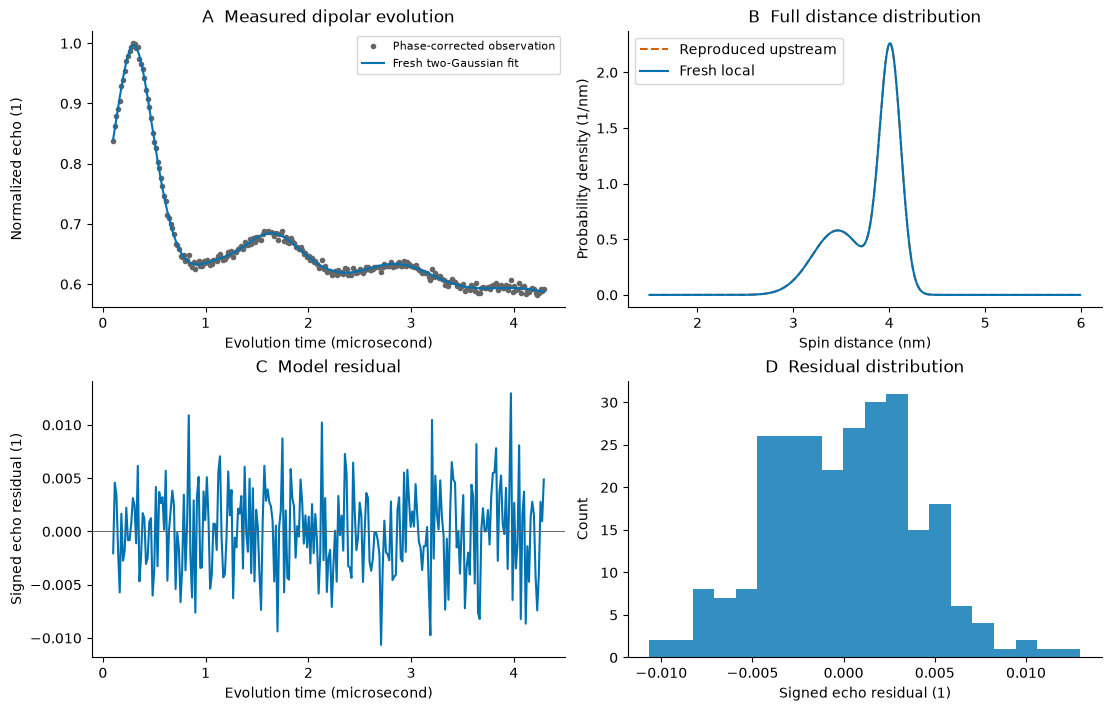

### Robustness

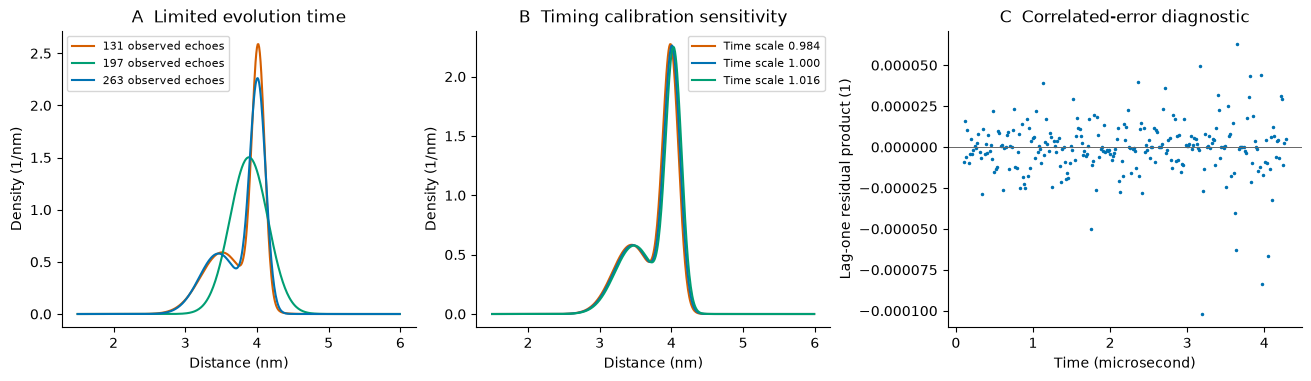

In [4]:
for figure_name,figure in figures.items():
    display(Markdown('### '+figure_name.replace('_',' ').title()))
    display(figure)
    plt.close(figure)

## Interpretation and limitations

The two-Gaussian model fits the full coherent echo and separates a narrow longer-distance population from a broader shorter-distance population. Finite-time and timing-scale studies show inference sensitivity. The histogram and lag-one residual diagnostic check model mismatch without assuming calibrated white-noise variance. Gaussian components use a fixed increasing-mean label convention. No confidence interval is claimed from these deterministic sensitivity curves; the upstream general examples include uncertainty machinery outside this selected point-estimate benchmark.

Agreement with the standard method establishes implementation fidelity. Independent mathematical tests check operators and signs, while measured residuals and sensitivity studies bound physical interpretation. No reconstruction is relabeled as ground truth.

## Sources

Fábregas Ibáñez, Jeschke and Stoll, DeerLab: a comprehensive software package for analyzing dipolar electron paramagnetic resonance spectroscopy data, Magnetic Resonance 1 (2020), 209–224. https://doi.org/10.5194/mr-1-209-2020

